# Step 4: Train a U-Net to find landslides

Goal: teach a neural network to look at a 14-band satellite patch and color in every pixel that is a landslide.

**Before running:**
- Run `01_explore_landslide4sense.ipynb` all the way through first. It saves `band_stats.npy`, which this notebook needs.
- Training runs on your M2's GPU (it shows up as `mps`). Expect roughly 1 minute per epoch, about 20–40 minutes total. Keep the laptop plugged in and awake.

In [8]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"  # lets any op the M2 GPU can't do fall back to CPU

import time, json
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

ROOT = Path.home() / "geoai"
DATA_DIR = ROOT / "data" / "TrainData"

if torch.backends.mps.is_available():
    device = torch.device("mps")      # Apple Silicon GPU
elif torch.cuda.is_available():
    device = torch.device("cuda")     # NVIDIA GPU (e.g. Colab)
else:
    device = torch.device("cpu")
print("Training on:", device)

torch.manual_seed(0)
np.random.seed(0)

Training on: mps


## Split the data
Only the training set has masks, so we hold back 15% of it as a **validation set**. The model never trains on these patches; we use them to measure how well it does on images it hasn't seen.

In [9]:
def read_h5(path):
    with h5py.File(path, "r") as f:
        return f[list(f.keys())[0]][:]

n = len(list((DATA_DIR / "img").glob("image_*.h5")))
ids = np.arange(1, n + 1)
np.random.default_rng(42).shuffle(ids)
n_val = int(0.15 * n)
val_ids, train_ids = ids[:n_val], ids[n_val:]
print(f"{len(train_ids)} training patches, {len(val_ids)} validation patches")

mean, std = np.load(ROOT / "band_stats.npy")
std = np.where(std < 1e-6, 1.0, std)

3230 training patches, 569 validation patches


## Dataset
Each item is one patch: the 14 bands (normalized so every band is on a similar scale) and its landslide mask.
For training patches we also randomly rotate and flip them. A landslide is still a landslide upside down, so this gives the model more variety for free.

In [10]:
class LandslideDataset(Dataset):
    def __init__(self, ids, augment=False):
        self.ids = ids
        self.augment = augment

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        i = int(self.ids[idx])
        img = read_h5(DATA_DIR / "img" / f"image_{i}.h5").astype(np.float32)
        mask = read_h5(DATA_DIR / "mask" / f"mask_{i}.h5").astype(np.float32)
        img = np.nan_to_num((img - mean) / std).astype(np.float32)
        img = img.transpose(2, 0, 1)  # (128, 128, 14) -> (14, 128, 128), the layout PyTorch expects

        if self.augment:
            k = np.random.randint(4)
            img, mask = np.rot90(img, k, axes=(1, 2)), np.rot90(mask, k)
            if np.random.rand() < 0.5:
                img, mask = img[:, :, ::-1], mask[:, ::-1]

        return torch.from_numpy(img.copy()), torch.from_numpy(mask.copy())[None]

train_ds = LandslideDataset(train_ids, augment=True)
val_ds = LandslideDataset(val_ids)
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)

x, y = train_ds[0]
print("One input:", tuple(x.shape), " one mask:", tuple(y.shape))

One input: (14, 128, 128)  one mask: (1, 128, 128)


## Class imbalance
Only a small share of pixels are landslides. A lazy model could predict "no landslide" everywhere and still be ~98% "accurate". To prevent that, we tell the loss function to weigh missed landslide pixels more heavily.

In [11]:
pos = sum(read_h5(DATA_DIR / "mask" / f"mask_{int(i)}.h5").sum() for i in train_ids)
total = len(train_ids) * 128 * 128
landslide_frac = pos / total
pos_weight = float(min((1 - landslide_frac) / landslide_frac, 10.0))
print(f"Landslide pixels: {landslide_frac:.2%} of training pixels")
print(f"Each landslide pixel will count {pos_weight:.1f}x in the loss")

Landslide pixels: 2.31% of training pixels
Each landslide pixel will count 10.0x in the loss


## The model: U-Net
U-Net is the standard architecture for this kind of pixel-by-pixel labeling.
- The **encoder** (left side of the "U") shrinks the image step by step, learning *what* is in it.
- The **decoder** (right side) grows it back to full size, deciding *where* each thing is.
- **Skip connections** pass fine detail straight across so the edges of landslides stay sharp.

In [12]:
def double_conv(c_in, c_out):
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
    )

class UNet(nn.Module):
    def __init__(self, in_ch=14, base=32):
        super().__init__()
        c1, c2, c3, c4, c5 = base, base * 2, base * 4, base * 8, base * 16
        self.pool = nn.MaxPool2d(2)
        self.enc1, self.enc2 = double_conv(in_ch, c1), double_conv(c1, c2)
        self.enc3, self.enc4 = double_conv(c2, c3), double_conv(c3, c4)
        self.bottleneck = double_conv(c4, c5)
        self.up4, self.dec4 = nn.ConvTranspose2d(c5, c4, 2, stride=2), double_conv(c5, c4)
        self.up3, self.dec3 = nn.ConvTranspose2d(c4, c3, 2, stride=2), double_conv(c4, c3)
        self.up2, self.dec2 = nn.ConvTranspose2d(c3, c2, 2, stride=2), double_conv(c3, c2)
        self.up1, self.dec1 = nn.ConvTranspose2d(c2, c1, 2, stride=2), double_conv(c2, c1)
        self.head = nn.Conv2d(c1, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)                      # 128x128
        e2 = self.enc2(self.pool(e1))          # 64x64
        e3 = self.enc3(self.pool(e2))          # 32x32
        e4 = self.enc4(self.pool(e3))          # 16x16
        b = self.bottleneck(self.pool(e4))     # 8x8
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)                   # one score per pixel

model = UNet().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million")
with torch.no_grad():
    print("Output shape:", tuple(model(x[None].to(device)).shape))

Parameters: 7.8 million
Output shape: (1, 1, 128, 128)


## Loss and metrics
**Loss** (what the model minimizes) = weighted BCE + Dice.
- BCE judges each pixel on its own.
- Dice judges how well the predicted landslide *shape* overlaps the real one.

**Metrics** (how we judge the model), all computed on landslide pixels only:
- **Precision**: of the pixels it called landslide, how many really were.
- **Recall**: of the real landslide pixels, how many it found.
- **F1**: the balance of the two. This is the main score the Landslide4Sense competition used.
- **IoU**: overlap between predicted and true landslide areas.

In [13]:
bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))

def dice_loss(logits, target, eps=1.0):
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(1, 2, 3))
    union = p.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return (1 - (2 * inter + eps) / (union + eps)).mean()

def loss_fn(logits, target):
    return bce(logits, target) + dice_loss(logits, target)

def scores(tp, fp, fn):
    precision = tp / (tp + fp + 1e-9)
    recall = tp / (tp + fn + 1e-9)
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    iou = tp / (tp + fp + fn + 1e-9)
    return dict(precision=precision, recall=recall, f1=f1, iou=iou)

@torch.no_grad()
def evaluate(model, loader, threshold=0.5):
    model.eval()
    tp = fp = fn = 0.0
    total_loss, count = 0.0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(x)
        count += len(x)
        pred = (torch.sigmoid(logits) > threshold).float()
        tp += (pred * y).sum().item()
        fp += (pred * (1 - y)).sum().item()
        fn += ((1 - pred) * y).sum().item()
    return dict(loss=total_loss / count, **scores(tp, fp, fn))

## Train
Each **epoch** is one full pass over the training patches. After every epoch we check the validation set and save the model whenever its F1 is the best so far, to `~/geoai/landslide_unet.pt`.

If you want a quick test run first, set `EPOCHS = 2`.

In [19]:
EPOCHS = 25

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
MODEL_PATH = ROOT / "landslide_unet.pt"

history, best_f1 = [], -1.0
n_batches = len(train_loader)
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, running, seen = time.time(), 0.0, 0
    for b, (x, y) in enumerate(train_loader, 1):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(x), y)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(x)
        seen += len(x)
        if b % 50 == 0:
            print(f"   epoch {epoch}: batch {b}/{n_batches} ({time.time() - t0:.0f}s)", flush=True)
    scheduler.step()

    print(f"   epoch {epoch}: checking validation set...", flush=True)
    val = evaluate(model, val_loader)
    history.append(dict(epoch=epoch, train_loss=running / seen, **val))

    note = ""
    if val["f1"] > best_f1:
        best_f1 = val["f1"]
        torch.save(model.state_dict(), MODEL_PATH)
        note = "  <- best so far, saved"
    print(f"Epoch {epoch:2d}/{EPOCHS} | train loss {running / seen:.3f} | val loss {val['loss']:.3f} "
          f"| F1 {val['f1']:.3f} | IoU {val['iou']:.3f} | {time.time() - t0:.0f}s{note}", flush=True)

print(f"\nBest validation F1: {best_f1:.3f}")

   epoch 1: batch 50/202 (16s)
   epoch 1: batch 100/202 (32s)
   epoch 1: batch 150/202 (48s)
   epoch 1: batch 200/202 (65s)
   epoch 1: checking validation set...
Epoch  1/25 | train loss 0.530 | val loss 0.474 | F1 0.666 | IoU 0.499 | 73s  <- best so far, saved
   epoch 2: batch 50/202 (20s)
   epoch 2: batch 100/202 (37s)
   epoch 2: batch 150/202 (57s)
   epoch 2: batch 200/202 (78s)
   epoch 2: checking validation set...
Epoch  2/25 | train loss 0.517 | val loss 0.466 | F1 0.702 | IoU 0.541 | 86s  <- best so far, saved
   epoch 3: batch 50/202 (21s)
   epoch 3: batch 100/202 (43s)
   epoch 3: batch 150/202 (66s)
   epoch 3: batch 200/202 (87s)
   epoch 3: checking validation set...
Epoch  3/25 | train loss 0.511 | val loss 0.482 | F1 0.721 | IoU 0.564 | 93s  <- best so far, saved
   epoch 4: batch 50/202 (21s)
   epoch 4: batch 100/202 (42s)
   epoch 4: batch 150/202 (63s)
   epoch 4: batch 200/202 (85s)
   epoch 4: checking validation set...
Epoch  4/25 | train loss 0.530 | val

In [20]:
import time
print("device:", device, "| MPS available:", torch.backends.mps.is_available(), "| MPS built:", torch.backends.mps.is_built())

t0 = time.time()
x, y = next(iter(train_loader))
print(f"loading one batch: {time.time() - t0:.2f}s")

model.train()
x, y = x.to(device), y.to(device)
for step in range(3):
    t0 = time.time()
    optimizer.zero_grad()
    loss = loss_fn(model(x), y)
    loss.backward()
    optimizer.step()
    loss.item()
    print(f"training step {step + 1}: {time.time() - t0:.2f}s")

print(f"=> roughly {len(train_loader) * (time.time() - t0) / 60:.1f} minutes per epoch")

device: mps | MPS available: True | MPS built: True
loading one batch: 0.10s
training step 1: 0.29s
training step 2: 0.30s
training step 3: 0.32s
=> roughly 1.1 minutes per epoch


## Learning curves
- **Loss**: both lines should go down. If training loss keeps falling while validation loss rises, the model is *overfitting*, meaning it is memorizing the training patches.
- **F1 / IoU**: these should climb and then level off.

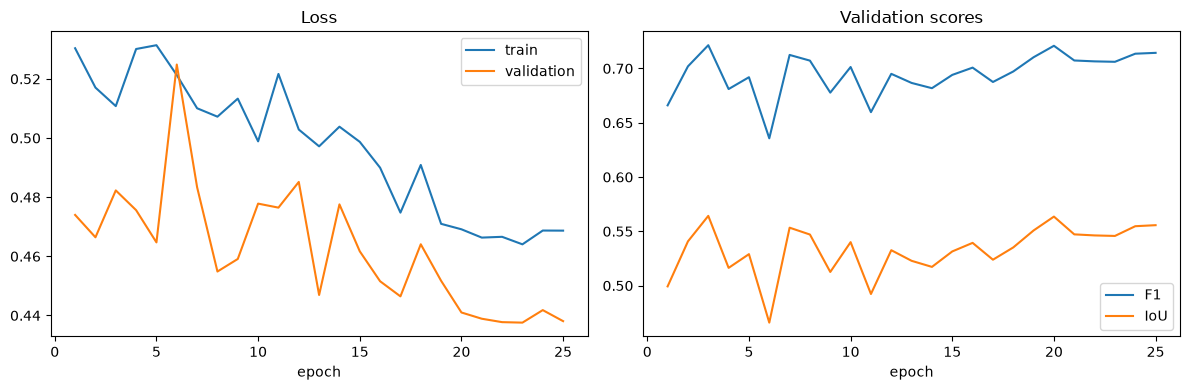

In [21]:
ep = [h["epoch"] for h in history]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ep, [h["train_loss"] for h in history], label="train")
ax1.plot(ep, [h["loss"] for h in history], label="validation")
ax1.set_title("Loss"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(ep, [h["f1"] for h in history], label="F1")
ax2.plot(ep, [h["iou"] for h in history], label="IoU")
ax2.set_title("Validation scores"); ax2.set_xlabel("epoch"); ax2.legend()
plt.tight_layout(); plt.show()

## Pick the best threshold
The model outputs a probability (0 to 1) for each pixel. By default anything above 0.5 counts as landslide, but a different cutoff often scores better. We try several and keep the one with the highest F1.

In [22]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))
model.eval()

probs, truths = [], []
with torch.no_grad():
    for x, y in val_loader:
        probs.append(torch.sigmoid(model(x.to(device))).cpu().numpy())
        truths.append(y.numpy())
probs, truths = np.concatenate(probs), np.concatenate(truths)

results = []
for t in np.arange(0.1, 0.91, 0.05):
    pred = probs > t
    tp = float((pred & (truths == 1)).sum())
    fp = float((pred & (truths == 0)).sum())
    fn = float((~pred & (truths == 1)).sum())
    results.append((t, scores(tp, fp, fn)))

best_t, best = max(results, key=lambda r: r[1]["f1"])
print(f"Best threshold: {best_t:.2f}")
print(f"  precision {best['precision']:.3f} | recall {best['recall']:.3f} | F1 {best['f1']:.3f} | IoU {best['iou']:.3f}")

with open(ROOT / "model_config.json", "w") as f:
    json.dump({"threshold": round(float(best_t), 2), "in_channels": 14, "base": 32, "val_f1": round(best["f1"], 4)}, f, indent=2)
print("Saved model_config.json")

Best threshold: 0.75
  precision 0.718 | recall 0.762 | F1 0.739 | IoU 0.586
Saved model_config.json


## See it in action
For the validation patches with the most landslide area: the satellite image, the true landslides, and what the model predicted.

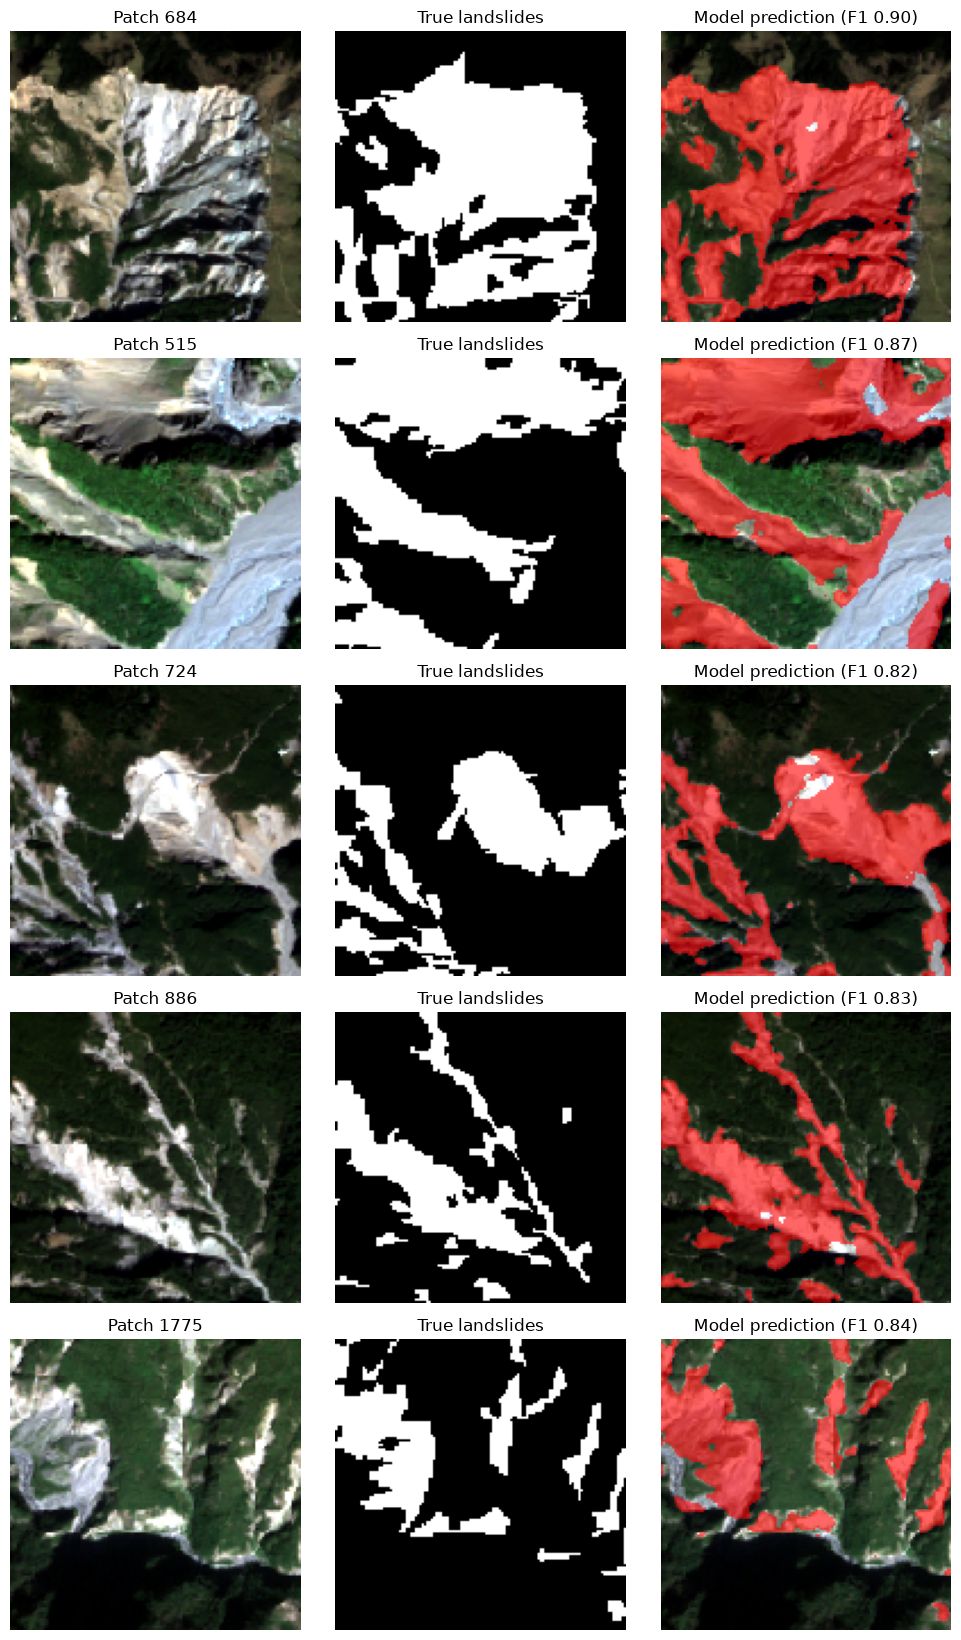

In [23]:
def stretch(a):
    lo, hi = np.percentile(a, (2, 98))
    return np.clip((a - lo) / (hi - lo + 1e-6), 0, 1)

def true_color(i):
    raw = read_h5(DATA_DIR / "img" / f"image_{i}.h5").astype(np.float32)
    return np.dstack([stretch(raw[:, :, b]) for b in (3, 2, 1)])

order = np.argsort(truths.sum(axis=(1, 2, 3)))[::-1][:5]
fig, axes = plt.subplots(len(order), 3, figsize=(10, 3.3 * len(order)))
for row, k in zip(axes, order):
    i = int(val_ids[k])
    pred = probs[k, 0] > best_t
    truth = truths[k, 0]
    tp = (pred & (truth == 1)).sum()
    f1 = 2 * tp / (pred.sum() + truth.sum() + 1e-9)
    row[0].imshow(true_color(i)); row[0].set_title(f"Patch {i}")
    row[1].imshow(truth, cmap="gray"); row[1].set_title("True landslides")
    row[2].imshow(true_color(i))
    row[2].imshow(np.ma.masked_where(~pred, pred), cmap="autumn", alpha=0.6)
    label = "correctly empty" if truth.sum() == 0 and pred.sum() == 0 else f"F1 {f1:.2f}"
    row[2].set_title(f"Model prediction ({label})")
    for ax in row:
        ax.axis("off")
plt.tight_layout(); plt.show()

## How to read your results
- For reference, the top teams in the 2022 Landslide4Sense competition reached an F1 of roughly 0.7 on the landslide class. A plain U-Net like this one landing in the 0.55–0.7 range is a solid result.
- **Low precision** (lots of false alarms): try raising the threshold, or lowering the `10.0` cap on `pos_weight`.
- **Low recall** (missing landslides): try lowering the threshold or training for more epochs.

**Files this notebook saved in `~/geoai/`:**
- `landslide_unet.pt`: the trained model weights
- `model_config.json`: the chosen threshold and model settings

Next up, Step 5: run this model on fresh Sentinel-2 imagery of Nepal.